### scipy: Anwendungen - Übungen

Im letzten Notebook der Reihe setzt du **scipy** für Anwendungen ein: Vorgänge, bei denen man die **Änderungsrate** kennt
(Wachstum, Abkühlung, Räuber und Beute, Ausbreitung einer Krankheit), Planungsaufgaben mit **linearer Optimierung**,
**Abstände** und nächste Nachbarn zwischen vielen Punkten sowie Naturkonstanten und Einheiten.

Die Reihe hat vier Notebooks:

1. Analysis: Nullstellen, Gleichungen, Extremstellen, Integrale
2. Messdaten auswerten: Interpolation, Ausgleichskurven, Spitzen finden
3. Stochastik: Verteilungen und Hypothesentests
4. **Anwendungen**: Änderungsraten und Modelle, lineare Optimierung, Abstände (dieses Notebook)

Vorausgesetzt werden *scipy: Analysis*, *numpy: Zweidimensionale Arrays* und *matplotlib: Grundlagen*.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Beim ersten `import scipy` lädt der Browser das Paket nach. Das dauert ein paar Sekunden.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ überlegst du zuerst, führst dann die Zelle aus und vergleichst.
Die aufklappbare Lösung erklärt dort, wie die Ausgabe zustande kommt.

## 1. Änderungsraten: solve_ivp

#### Von der Änderungsrate zum Verlauf

Oft weiß man nicht, wie sich eine Größe `y` im Lauf der Zeit verhält, sondern nur, **wie schnell sie sich ändert**. Bei einer Bakterienkultur
wächst die Anzahl pro Stunde um 30 % des aktuellen Bestands: Die Änderungsrate ist `y' = 0.3 · y`. Eine solche Gleichung,
in der die Ableitung vorkommt, heißt **Differentialgleichung**.

`integrate.solve_ivp(f, (t0, t1), [y0])` berechnet den Verlauf schrittweise (*solve initial value problem*, Anfangswertproblem):

- `f(t, y)` ist eine Funktion, die zu Zeit `t` und Bestand `y` die **Änderungsrate** zurückgibt. Sie muss `t` als ersten Parameter haben,
  auch wenn sie ihn nicht benutzt.
- `(t0, t1)` ist der Zeitraum, `[y0]` der **Anfangsbestand** (als Liste, weil es auch mehrere Größen sein können, siehe Abschnitt 3).
- `t_eval=[...]` gibt die Zeitpunkte an, für die man Werte haben will.

Das Ergebnis hat die Attribute `t` (die Zeitpunkte) und `y` (ein 2D-Array: Zeile 0 sind die Werte der ersten Größe).

In [ ]:
import numpy as np
from scipy import integrate


def rate(t, y):
    return 0.3 * y


loesung = integrate.solve_ivp(rate, (0, 5), [100], t_eval=[0, 1, 2, 3, 4, 5], rtol=1e-8, atol=1e-8)
print(loesung.t)
print(np.round(loesung.y[0], 2))
print(np.round(100 * np.exp(0.3 * loesung.t), 2))

#### Genauigkeit: `rtol` und `atol`

`solve_ivp()` geht in kleinen Zeitschritten vor und schätzt dabei seinen Fehler. Ohne Angabe ist es nur auf etwa 3 Stellen genau
(das reicht für Diagramme). Mit `rtol=1e-8, atol=1e-8` (relativer und absoluter Fehler höchstens etwa 10⁻⁸) wird es sehr genau.
In diesem Notebook wird deshalb immer mit diesen Angaben gerechnet.

In [ ]:
import numpy as np
from scipy import integrate


def rate(t, y):
    return 0.3 * y


grob = integrate.solve_ivp(rate, (0, 5), [100], t_eval=[5])
genau = integrate.solve_ivp(rate, (0, 5), [100], t_eval=[5], rtol=1e-8, atol=1e-8)
print(grob.y[0, 0])
print(genau.y[0, 0])
print(100 * np.exp(1.5))

#### Den Verlauf zeichnen

Für ein Diagramm gibt man mit `t_eval=np.linspace(t0, t1, 200)` viele Zeitpunkte an und zeichnet `loesung.y[0]` über `loesung.t`.

In [ ]:
import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt


def rate(t, y):
    return 0.3 * y


loesung = integrate.solve_ivp(rate, (0, 5), [100], t_eval=np.linspace(0, 5, 200), rtol=1e-8, atol=1e-8)
plt.plot(loesung.t, loesung.y[0])
plt.xlabel('Zeit in h')
plt.ylabel('Bakterien')
plt.show()

#### Aufgabe 1.1

Ein Kapital von 2000 € wächst stetig mit 4 % pro Jahr: `y' = 0.04 · y`. Berechne mit `solve_ivp()` das Kapital nach 0, 5, 10, 15 und 20 Jahren
(`rtol=1e-8, atol=1e-8`) und gib die Werte auf zwei Nachkommastellen aus.

**Erwartete Ausgabe:**
```
[2000.   2442.81 2983.65 3644.24 4451.08]
```

In [ ]:
import numpy as np
from scipy import integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def rate(t, y):
    return 0.04 * y


loesung = integrate.solve_ivp(rate, (0, 20), [2000], t_eval=[0, 5, 10, 15, 20], rtol=1e-8, atol=1e-8)
print(np.round(loesung.y[0], 2))
```

</details>

#### Aufgabe 1.2

Vergleiche das Ergebnis der vorigen Aufgabe mit der Formel `2000 · e^(0.04 t)`: Gib für dieselben Zeitpunkte die größte Abweichung aus
(mit `:.1e`).

In [ ]:
import numpy as np
from scipy import integrate
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def rate(t, y):
    return 0.04 * y


zeiten = np.array([0, 5, 10, 15, 20])
loesung = integrate.solve_ivp(rate, (0, 20), [2000], t_eval=zeiten, rtol=1e-8, atol=1e-8)
print(f'{np.abs(loesung.y[0] - 2000 * np.exp(0.04 * zeiten)).max():.1e}')
```

</details>

#### Aufgabe 1.3

Ein radioaktiver Stoff zerfällt: `y' = -0.0866 · y` (`t` in Tagen). Zu Beginn sind 80 g vorhanden. Gib die Masse nach 8, 16 und 24 Tagen aus
(zwei Nachkommastellen, `rtol=1e-8, atol=1e-8`). Die Halbwertszeit ist etwa 8 Tage.

**Erwartete Ausgabe:**
```
[40.01 20.01 10.01]
```

In [ ]:
import numpy as np
from scipy import integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def rate(t, y):
    return -0.0866 * y


loesung = integrate.solve_ivp(rate, (0, 24), [80], t_eval=[8, 16, 24], rtol=1e-8, atol=1e-8)
print(np.round(loesung.y[0], 2))
```

</details>

#### Aufgabe 1.4

In einen Teich fließt ein Schadstoff mit konstant 3 kg pro Tag, gleichzeitig wird jeden Tag 10 % des vorhandenen Schadstoffs abgebaut:
`y' = 3 - 0.1 · y`. Zu Beginn sind 0 kg im Teich. Gib die Menge nach 10, 20, 50 und 100 Tagen aus (zwei Nachkommastellen, `rtol=1e-8, atol=1e-8`).
Welchem Wert nähert sie sich?

**Erwartete Ausgabe:**
```
[18.96 25.94 29.8  30.  ]
```

In [ ]:
import numpy as np
from scipy import integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def rate(t, y):
    return 3 - 0.1 * y


loesung = integrate.solve_ivp(rate, (0, 100), [0], t_eval=[10, 20, 50, 100], rtol=1e-8, atol=1e-8)
print(np.round(loesung.y[0], 2))
```

</details>

#### Aufgabe 1.5

Die Änderungsrate darf auch von der Zeit abhängen. Ein Speicher wird mit `y' = 5 + 2 · sin(t)` (Liter pro Minute) gefüllt und enthält zu Beginn 10 Liter.
Gib die Füllmenge nach 10 Minuten aus (zwei Nachkommastellen, `rtol=1e-8, atol=1e-8`) und vergleiche mit dem Integral `10 + ∫ (5 + 2 sin(t)) dt` von 0 bis 10 (`quad()`).

**Erwartete Ausgabe:**
```
63.68
63.68
```

In [ ]:
import numpy as np
from scipy import integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def zufluss(t):
    return 5 + 2 * np.sin(t)


def rate(t, y):
    return zufluss(t)


loesung = integrate.solve_ivp(rate, (0, 10), [10], t_eval=[10], rtol=1e-8, atol=1e-8)
print(round(loesung.y[0, 0], 2))
print(round(10 + integrate.quad(zufluss, 0, 10)[0], 2))
```

</details>

#### Aufgabe 1.6

Zeichne das Wachstum der Bakterien (`y' = 0.3 · y`, Start 100) mit `solve_ivp()` (200 Punkte von 0 bis 10, `rtol=1e-8, atol=1e-8`) als blaue Linie
und die Werte nach der Formel `100 · e^(0.3 t)` für die ganzen Stunden 0 bis 10 als rote Punkte. Die Punkte sollen genau auf der Linie liegen.

**Erwartete Ausgabe:**

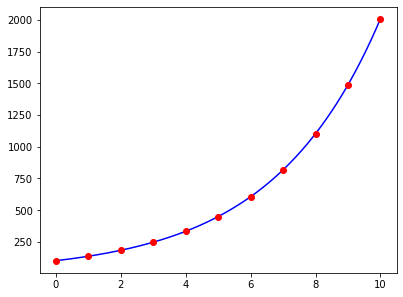

In [ ]:
import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt


def rate(t, y):
    return 0.3 * y


loesung = integrate.solve_ivp(rate, (0, 10), [100], t_eval=np.linspace(0, 10, 200), rtol=1e-8, atol=1e-8)
plt.plot(loesung.t, loesung.y[0], color='blue')
stunden = np.arange(11)
plt.plot(stunden, 100 * np.exp(0.3 * stunden), 'ro')
plt.show()
```

</details>

#### Aufgabe 1.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from scipy import integrate


def rate(t, y):
    return 2


loesung = integrate.solve_ivp(rate, (0, 3), [5], t_eval=[0, 1, 2, 3], rtol=1e-8, atol=1e-8)
print(loesung.y.shape)
print(loesung.y[0].round(4))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
(1, 4)
[ 5.  7.  9. 11.]
```

- `y` hat eine Zeile (eine Größe) und eine Spalte pro Zeitpunkt in `t_eval`: `(1, 4)`.
- Die Änderungsrate ist immer 2, der Bestand steigt also pro Zeiteinheit um 2, ausgehend von 5: `[ 5.  7.  9. 11.]`.

</details>

## 2. Wachstumsmodelle mit Parametern

#### Parameter mit `args=`

Viele Modelle haben **Parameter**, z. B. die Wachstumsrate `k` und die **Kapazitätsgrenze** `G` beim **logistischen Wachstum**:
`y' = k · y · (1 - y / G)`. Am Anfang wächst der Bestand fast exponentiell, in der Nähe von `G` wird das Wachstum immer langsamer.

Die Parameter schreibt man hinter `t` und `y` in die Funktion und gibt ihre Werte wie bei `quad()` mit `args=(...)` an.

In [ ]:
import numpy as np
from scipy import integrate


def logistisch(t, y, k, g):
    return k * y * (1 - y / g)


loesung = integrate.solve_ivp(logistisch, (0, 30), [10], t_eval=[0, 5, 10, 15, 20, 30], args=(0.4, 1000), rtol=1e-8, atol=1e-8)
print(np.round(loesung.y[0], 1))

#### Wann wird ein Wert erreicht? `dense_output=True`

Mit `dense_output=True` kann man die Lösung danach an **jeder** Stelle auswerten: `loesung.sol(t)` gibt ein Array mit den Werten aller Größen
zur Zeit `t`. Damit findet man mit `brentq()` aus *scipy: Analysis*, wann ein bestimmter Wert erreicht wird.

In [ ]:
from scipy import integrate, optimize


def logistisch(t, y, k, g):
    return k * y * (1 - y / g)


loesung = integrate.solve_ivp(logistisch, (0, 30), [10], args=(0.4, 1000), dense_output=True, rtol=1e-8, atol=1e-8)
print(round(loesung.sol(12.5)[0], 2))


def h(t):
    return loesung.sol(t)[0] - 500


print(round(optimize.brentq(h, 0, 30), 2))

#### Aufgabe 2.1

Auf einer Insel werden 20 Kaninchen ausgesetzt. Die Insel bietet Platz für 2000 Kaninchen, die Wachstumsrate ist `k = 0.8` pro Jahr.
Gib den Bestand (ganze Tiere) nach 0, 2, 4, 6, 8 und 10 Jahren aus (`rtol=1e-8, atol=1e-8`).

**Erwartete Ausgabe:**
```
[  20   95  397 1102 1717 1936]
```

In [ ]:
import numpy as np
from scipy import integrate


def logistisch(t, y, k, g):
    return k * y * (1 - y / g)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def logistisch(t, y, k, g):
    return k * y * (1 - y / g)

loesung = integrate.solve_ivp(logistisch, (0, 10), [20], t_eval=[0, 2, 4, 6, 8, 10], args=(0.8, 2000), rtol=1e-8, atol=1e-8)
print(np.round(loesung.y[0]).astype(int))
```

</details>

#### Aufgabe 2.2

Wann sind es nach dem Modell der vorigen Aufgabe 1000 Kaninchen, wann 1900? Benutze `dense_output=True` und `brentq()` im Intervall von 0 bis 20
(zwei Nachkommastellen).

**Erwartete Ausgabe:**
```
1000 5.74
1900 9.42
```

In [ ]:
import numpy as np
from scipy import integrate, optimize


def logistisch(t, y, k, g):
    return k * y * (1 - y / g)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate, optimize


def logistisch(t, y, k, g):
    return k * y * (1 - y / g)

loesung = integrate.solve_ivp(logistisch, (0, 20), [20], args=(0.8, 2000), dense_output=True, rtol=1e-8, atol=1e-8)
for ziel in [1000, 1900]:
    def h(t):
        return loesung.sol(t)[0] - ziel
    print(ziel, round(optimize.brentq(h, 0, 20), 2))
```

</details>

#### Aufgabe 2.3

Zeichne das logistische Wachstum der Kaninchen für die Wachstumsraten `k` = 0.4, 0.8 und 1.2 (jeweils 200 Punkte von 0 bis 20) in ein Diagramm
mit Legende (`k = 0.4` usw.) und der Kapazitätsgrenze als gestrichelter grauer Linie.

**Erwartete Ausgabe:**

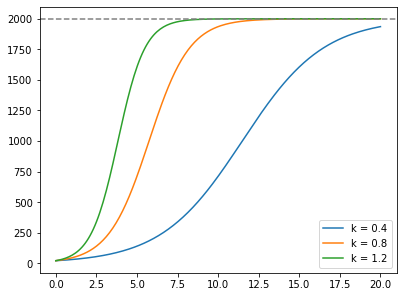

In [ ]:
import numpy as np
from scipy import integrate


def logistisch(t, y, k, g):
    return k * y * (1 - y / g)
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def logistisch(t, y, k, g):
    return k * y * (1 - y / g)
import matplotlib.pyplot as plt

zeit = np.linspace(0, 20, 200)
for k in [0.4, 0.8, 1.2]:
    loesung = integrate.solve_ivp(logistisch, (0, 20), [20], t_eval=zeit, args=(k, 2000), rtol=1e-8, atol=1e-8)
    plt.plot(loesung.t, loesung.y[0], label=f'k = {k}')
plt.axhline(2000, color='gray', linestyle='--')
plt.legend()
plt.show()
```

</details>

#### Aufgabe 2.4

**Abkühlung nach Newton:** Ein Kuchen kommt mit 180 °C aus dem Ofen in einen 20 °C warmen Raum. Seine Temperatur ändert sich mit
`T' = -k · (T - u)` (`u`: Raumtemperatur, `k = 0.07` pro Minute). Schreibe die Funktion mit den Parametern `k` und `u`, gib die Temperatur nach 10, 20 und 30 Minuten aus
(eine Nachkommastelle) und die Zeit, nach der der Kuchen nur noch 40 °C hat (zwei Nachkommastellen, `brentq()` zwischen 0 und 60).

**Erwartete Ausgabe:**
```
10 99.5
20 59.5
30 39.6
29.71
```

In [ ]:
import numpy as np
from scipy import integrate, optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate, optimize


def abkuehlung(t, temp, k, u):
    return -k * (temp - u)


loesung = integrate.solve_ivp(abkuehlung, (0, 60), [180], args=(0.07, 20), dense_output=True, rtol=1e-8, atol=1e-8)
for minute in [10, 20, 30]:
    print(minute, round(loesung.sol(minute)[0], 1))


def h(t):
    return loesung.sol(t)[0] - 40


print(round(optimize.brentq(h, 0, 60), 2))
```

</details>

#### Aufgabe 2.5

Ein Fischteich wird befischt: Pro Jahr werden `e` Tonnen Fisch entnommen. Das Modell ist `y' = 0.5 · y · (1 - y / 100) - e` (Start 60 Tonnen).
Gib für `e` = 5, 10 und 12 den Bestand nach 20 Jahren aus (eine Nachkommastelle, `rtol=1e-8, atol=1e-8`).
Je mehr entnommen wird, desto kleiner wird der Bestand, auf den sich der Teich einpendelt.

**Erwartete Ausgabe:**
```
5 88.7
10 72.2
12 60.0
```

In [ ]:
import numpy as np
from scipy import integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def fischerei(t, y, e):
    return 0.5 * y * (1 - y / 100) - e


for e in [5, 10, 12]:
    loesung = integrate.solve_ivp(fischerei, (0, 20), [60], t_eval=[20], args=(e,), rtol=1e-8, atol=1e-8)
    print(e, round(loesung.y[0, 0], 1))
```

</details>

#### Aufgabe 2.6

Ein Medikament wird über eine Infusion mit 2 mg pro Stunde zugeführt und mit der Rate `k = 0.25` pro Stunde abgebaut: `y' = 2 - k · y` (Start 0 mg).
Gib die Menge nach 4, 8, 12 und 24 Stunden aus (zwei Nachkommastellen) und vergleiche den letzten Wert mit dem Grenzwert `2 / k`.

**Erwartete Ausgabe:**
```
[5.06 6.92 7.6  7.98]
8.0
```

In [ ]:
import numpy as np
from scipy import integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def infusion(t, y, zufuhr, k):
    return zufuhr - k * y


loesung = integrate.solve_ivp(infusion, (0, 24), [0], t_eval=[4, 8, 12, 24], args=(2, 0.25), rtol=1e-8, atol=1e-8)
print(np.round(loesung.y[0], 2))
print(2 / 0.25)
```

</details>

#### Aufgabe 2.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np
from scipy import integrate


def logistisch(t, y, k, g):
    return k * y * (1 - y / g)


loesung = integrate.solve_ivp(logistisch, (0, 10), [500], t_eval=[0, 10], args=(0.5, 500), rtol=1e-8, atol=1e-8)
print(np.round(loesung.y[0], 2))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
[500. 500.]
```

Der Bestand startet genau an der Kapazitätsgrenze 500. Dort ist `1 - y / g = 0`, die Änderungsrate also 0.
Der Bestand bleibt die ganze Zeit 500: `[500. 500.]`.

</details>

## 3. Mehrere Größen: Räuber und Beute, Epidemien, Bewegungen

#### Systeme von Änderungsraten

Hängen mehrere Größen voneinander ab, ist `y` eine Liste mit allen Größen, und die Funktion gibt eine Liste mit allen Änderungsraten zurück.

Beispiel **Räuber und Beute** (Modell von Lotka und Volterra): Hasen `h` vermehren sich und werden von Füchsen `f` gefressen,
Füchse vermehren sich, wenn es viele Hasen gibt, und sterben sonst:

- `h' = a · h - b · h · f`
- `f' = c · h · f - d · f`

`loesung.y[0]` sind dann die Hasen, `loesung.y[1]` die Füchse.

In [ ]:
import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt


def raeuber_beute(t, y, a, b, c, d):
    h, f = y
    return [a * h - b * h * f, c * h * f - d * f]


loesung = integrate.solve_ivp(raeuber_beute, (0, 40), [40, 9], t_eval=np.linspace(0, 40, 400),
                              args=(0.6, 0.03, 0.01, 0.5), rtol=1e-8, atol=1e-8)
plt.plot(loesung.t, loesung.y[0], label='Hasen')
plt.plot(loesung.t, loesung.y[1], label='Füchse')
plt.legend()
plt.show()

#### Bewegungen: Ort und Geschwindigkeit

Bei Bewegungen kennt man die **Beschleunigung** (die Änderungsrate der Geschwindigkeit `v`), und die Geschwindigkeit ist die Änderungsrate
des Orts `s`. Man rechnet also mit den beiden Größen `[s, v]`: `s' = v` und `v' = Beschleunigung`.

Beispiel freier Fall aus 100 m Höhe ohne Luftwiderstand: `v' = -9.81`. Die Höhe nach 2 Sekunden ist nach der Formel `100 - 9.81/2 · 2² = 80.38 m`.

In [ ]:
from scipy import integrate


def fall(t, y):
    s, v = y
    return [v, -9.81]


loesung = integrate.solve_ivp(fall, (0, 4), [100, 0], t_eval=[0, 1, 2, 3, 4], rtol=1e-8, atol=1e-8)
print(loesung.y[0].round(3))
print(loesung.y[1].round(2))

#### Aufgabe 3.1

Gib für das Räuber-Beute-Modell aus dem Beispiel (Start 40 Hasen und 9 Füchse, Parameter `0.6, 0.03, 0.01, 0.5`) die Anzahl der Hasen und Füchse
nach 0, 5, 10, 15 und 20 Jahren aus (eine Nachkommastelle, `rtol=1e-8, atol=1e-8`).

**Erwartete Ausgabe:**
```
[40.  71.4 22.8 96.4 20.8]
[ 9.  35.8 13.6 14.8 24.7]
```

In [ ]:
import numpy as np
from scipy import integrate


def raeuber_beute(t, y, a, b, c, d):
    h, f = y
    return [a * h - b * h * f, c * h * f - d * f]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def raeuber_beute(t, y, a, b, c, d):
    h, f = y
    return [a * h - b * h * f, c * h * f - d * f]

loesung = integrate.solve_ivp(raeuber_beute, (0, 20), [40, 9], t_eval=[0, 5, 10, 15, 20], args=(0.6, 0.03, 0.01, 0.5), rtol=1e-8, atol=1e-8)
print(np.round(loesung.y[0], 1))
print(np.round(loesung.y[1], 1))
```

</details>

#### Aufgabe 3.2

Bestimme im Räuber-Beute-Modell (Zeitraum 0 bis 40, 4001 Zeitpunkte) die größte Anzahl von Hasen und von Füchsen und wann sie zum ersten Mal erreicht wird
(Zeitpunkt mit einer Nachkommastelle, Anzahl mit einer Nachkommastelle).

**Erwartete Ausgabe:**
```
Hasen 15.6 101.4
Füchse 29.8 38.4
```

In [ ]:
import numpy as np
from scipy import integrate


def raeuber_beute(t, y, a, b, c, d):
    h, f = y
    return [a * h - b * h * f, c * h * f - d * f]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def raeuber_beute(t, y, a, b, c, d):
    h, f = y
    return [a * h - b * h * f, c * h * f - d * f]

loesung = integrate.solve_ivp(raeuber_beute, (0, 40), [40, 9], t_eval=np.linspace(0, 40, 4001), args=(0.6, 0.03, 0.01, 0.5), rtol=1e-8, atol=1e-8)
for name, werte in [('Hasen', loesung.y[0]), ('Füchse', loesung.y[1])]:
    i = werte.argmax()
    print(name, round(loesung.t[i], 1), round(werte[i], 1))
```

</details>

#### Aufgabe 3.3

Zeichne für das Räuber-Beute-Modell (0 bis 40, 400 Punkte) die Füchse über den Hasen (x-Achse: Hasen, y-Achse: Füchse). Es entsteht eine geschlossene
Kurve, weil sich der Verlauf immer wiederholt. Beschrifte die Achsen und markiere den Startpunkt (40 | 9) als roten Punkt.

**Erwartete Ausgabe:**

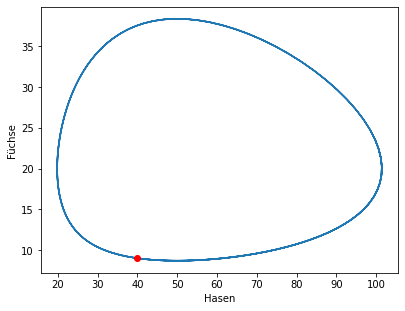

In [ ]:
import numpy as np
from scipy import integrate


def raeuber_beute(t, y, a, b, c, d):
    h, f = y
    return [a * h - b * h * f, c * h * f - d * f]
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def raeuber_beute(t, y, a, b, c, d):
    h, f = y
    return [a * h - b * h * f, c * h * f - d * f]
import matplotlib.pyplot as plt

loesung = integrate.solve_ivp(raeuber_beute, (0, 40), [40, 9], t_eval=np.linspace(0, 40, 400), args=(0.6, 0.03, 0.01, 0.5), rtol=1e-8, atol=1e-8)
plt.plot(loesung.y[0], loesung.y[1])
plt.plot(40, 9, 'ro')
plt.xlabel('Hasen')
plt.ylabel('Füchse')
plt.show()
```

</details>

#### Aufgabe 3.4

**Ausbreitung einer Krankheit (SIR-Modell):** Die Anteile der Bevölkerung sind `s` (noch nicht erkrankt), `i` (gerade krank, ansteckend) und `r` (genesen).
Mit der Ansteckungsrate `β = 0.3` und der Genesungsrate `γ = 0.1` pro Tag gilt das Modell in der Zelle. Zu Beginn sind 1 % krank (`[0.99, 0.01, 0]`).
Gib die drei Anteile nach 0, 30, 60, 90 und 120 Tagen zeilenweise mit ihrem Namen aus (4 Nachkommastellen, `rtol=1e-8, atol=1e-8`).

**Erwartete Ausgabe:**
```
s [0.99   0.2464 0.0683 0.0596 0.0589]
i [0.01   0.29   0.0405 0.0035 0.0003]
r [0.     0.4636 0.8912 0.9369 0.9408]
```

In [ ]:
import numpy as np
from scipy import integrate


def sir(t, y, beta, gamma):
    s, i, r = y
    return [-beta * s * i, beta * s * i - gamma * i, gamma * i]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def sir(t, y, beta, gamma):
    s, i, r = y
    return [-beta * s * i, beta * s * i - gamma * i, gamma * i]

loesung = integrate.solve_ivp(sir, (0, 120), [0.99, 0.01, 0], t_eval=[0, 30, 60, 90, 120], args=(0.3, 0.1), rtol=1e-8, atol=1e-8)
for name, werte in zip(['s', 'i', 'r'], loesung.y):
    print(name, np.round(werte, 4))
```

</details>

#### Aufgabe 3.5

Bestimme im SIR-Modell (0 bis 160 Tage, 1601 Zeitpunkte) den Tag mit den meisten Kranken und ihren Anteil (eine bzw. 4 Nachkommastellen) und den Anteil,
der am Ende nie krank war. Wiederhole das mit der halben Ansteckungsrate `β = 0.15` (z. B. durch Abstandsregeln).

**Erwartete Ausgabe:**
```
0.3 26.6 0.3038 0.0588
0.15 65.1 0.0697 0.415
```

In [ ]:
import numpy as np
from scipy import integrate


def sir(t, y, beta, gamma):
    s, i, r = y
    return [-beta * s * i, beta * s * i - gamma * i, gamma * i]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def sir(t, y, beta, gamma):
    s, i, r = y
    return [-beta * s * i, beta * s * i - gamma * i, gamma * i]

zeit = np.linspace(0, 160, 1601)
for beta in [0.3, 0.15]:
    loesung = integrate.solve_ivp(sir, (0, 160), [0.99, 0.01, 0], t_eval=zeit, args=(beta, 0.1), rtol=1e-8, atol=1e-8)
    i = loesung.y[1].argmax()
    print(beta, round(loesung.t[i], 1), round(loesung.y[1, i], 4), round(loesung.y[0, -1], 4))
```

</details>

#### Aufgabe 3.6

Zeichne die drei Anteile des SIR-Modells mit `β = 0.3` (0 bis 160 Tage, 400 Punkte) in ein Diagramm: `s` blau, `i` rot, `r` grün, mit Legende
(`nicht erkrankt`, `krank`, `genesen`) und der x-Achsen-Beschriftung `Tage`.

**Erwartete Ausgabe:**

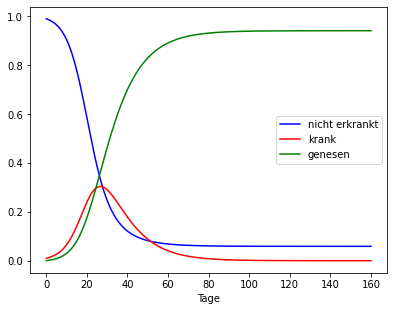

In [ ]:
import numpy as np
from scipy import integrate


def sir(t, y, beta, gamma):
    s, i, r = y
    return [-beta * s * i, beta * s * i - gamma * i, gamma * i]
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def sir(t, y, beta, gamma):
    s, i, r = y
    return [-beta * s * i, beta * s * i - gamma * i, gamma * i]
import matplotlib.pyplot as plt

loesung = integrate.solve_ivp(sir, (0, 160), [0.99, 0.01, 0], t_eval=np.linspace(0, 160, 400), args=(0.3, 0.1), rtol=1e-8, atol=1e-8)
plt.plot(loesung.t, loesung.y[0], color='blue', label='nicht erkrankt')
plt.plot(loesung.t, loesung.y[1], color='red', label='krank')
plt.plot(loesung.t, loesung.y[2], color='green', label='genesen')
plt.xlabel('Tage')
plt.legend()
plt.show()
```

</details>

#### Aufgabe 3.7

**Fall mit Luftwiderstand:** Ein Fallschirmspringer (80 kg) fällt aus dem Stand. Mit Luftwiderstand ist `v' = -9.81 + 0.25 / 80 · v²`
(`v` ist negativ, weil es nach unten geht). Gib die Geschwindigkeit in km/h nach 5, 10, 20 und 30 Sekunden aus (eine Nachkommastelle, `rtol=1e-8, atol=1e-8`)
und die Grenzgeschwindigkeit `√(9.81 · 80 / 0.25)` in km/h.

**Erwartete Ausgabe:**
```
[142.  189.9 201.3 201.7]
201.7
```

In [ ]:
import numpy as np
from scipy import integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def fall(t, y):
    s, v = y
    return [v, -9.81 + 0.25 / 80 * v ** 2]


loesung = integrate.solve_ivp(fall, (0, 30), [4000, 0], t_eval=[5, 10, 20, 30], rtol=1e-8, atol=1e-8)
print(np.round(-loesung.y[1] * 3.6, 1))
print(round(np.sqrt(9.81 * 80 / 0.25) * 3.6, 1))
```

</details>

#### Aufgabe 3.8

Ein Ball wird aus 2 m Höhe mit 15 m/s senkrecht nach oben geworfen (Höhe `s`, Geschwindigkeit `v`, `v' = -9.81`). Wann landet er auf dem Boden?
Benutze `dense_output=True` und `brentq()` für die Höhe 0 im Intervall von 1 bis 5 und gib auch die Aufprallgeschwindigkeit aus (zwei Nachkommastellen).

**Erwartete Ausgabe:**
```
3.19
-16.26
```

In [ ]:
import numpy as np
from scipy import integrate, optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate, optimize


def wurf(t, y):
    s, v = y
    return [v, -9.81]


loesung = integrate.solve_ivp(wurf, (0, 5), [2, 15], dense_output=True, rtol=1e-8, atol=1e-8)


def hoehe(t):
    return loesung.sol(t)[0]


landung = optimize.brentq(hoehe, 1, 5)
print(round(landung, 2))
print(round(loesung.sol(landung)[1], 2))
```

</details>

#### Aufgabe 3.9

**Federpendel:** Eine Masse an einer Feder schwingt. Für die Auslenkung `x` und die Geschwindigkeit `v` gilt `x' = v` und `v' = -4 · x - 0.2 · v`
(die Feder zieht zurück, die Reibung bremst). Start: `x = 1`, `v = 0`. Zeichne die Auslenkung für 0 bis 30 Sekunden (600 Punkte, `rtol=1e-8, atol=1e-8`) und
gib die Zeitpunkte der ersten drei Maxima nach dem Start aus (mit `signal.find_peaks()` aus *scipy: Messdaten*, zwei Nachkommastellen).

**Erwartete Ausgabe:**
```
[3.16 6.31 9.42]
```

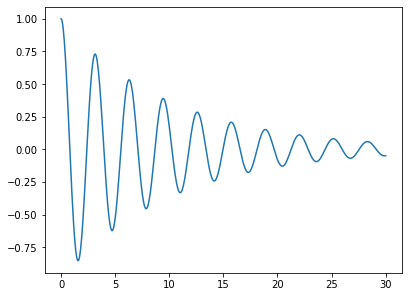

In [ ]:
import numpy as np
from scipy import integrate
from scipy import signal
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate
from scipy import signal
import matplotlib.pyplot as plt


def feder(t, y):
    x, v = y
    return [v, -4 * x - 0.2 * v]


loesung = integrate.solve_ivp(feder, (0, 30), [1, 0], t_eval=np.linspace(0, 30, 600), rtol=1e-8, atol=1e-8)
spitzen = signal.find_peaks(loesung.y[0])[0]
print(np.round(loesung.t[spitzen[:3]], 2))
plt.plot(loesung.t, loesung.y[0])
plt.show()
```

</details>

#### Aufgabe 3.10

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from scipy import integrate


def bewegung(t, y):
    s, v = y
    return [v, 0]


loesung = integrate.solve_ivp(bewegung, (0, 4), [10, 3], t_eval=[0, 2, 4], rtol=1e-8, atol=1e-8)
print(loesung.y.round(2))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
[[10. 16. 22.]
 [ 3.  3.  3.]]
```

Die Beschleunigung ist 0, die Geschwindigkeit bleibt also 3 (zweite Zeile). Der Ort startet bei 10 und nimmt pro Sekunde um 3 zu:
10, 16, 22 (erste Zeile). Ausgabe: `[[10. 16. 22.]` und `[ 3.  3.  3.]]`.

</details>

## 4. Lineare Optimierung

#### `optimize.linprog()`

Eine Firma stellt zwei Produkte her und will den Gewinn maximieren. Die Produktion ist durch **Nebenbedingungen** begrenzt (Maschinenzeit, Material).
Sind Gewinn und Nebenbedingungen **linear** (keine Quadrate, keine Produkte der Variablen), heißt das **lineare Optimierung**.

`optimize.linprog(c, A_ub=A, b_ub=b, bounds=...)` sucht die Werte `x`, für die `c · x` (die Summe `c[0]·x[0] + c[1]·x[1] + ...`) **möglichst klein** ist,
unter den Bedingungen `A · x ≤ b` (jede Zeile von `A` mit `b` ist eine Ungleichung, *ub* heißt *upper bound*).
`bounds` gibt für jede Variable den Bereich als Tupel an, `(0, None)` heißt „mindestens 0, nach oben unbegrenzt“ (das ist auch der Standard).

Um zu **maximieren**, minimiert man `-c` und nimmt beim Ergebnis das Vorzeichen zurück. Das Ergebnis hat die Attribute `x` (die beste Lösung),
`fun` (der Wert von `c · x` dort) und `success` (ob eine Lösung gefunden wurde).

Beispiel: Tische bringen 30 € Gewinn, Stühle 40 €. Ein Tisch braucht 2 h Tischlerei und 4 h Lackiererei, ein Stuhl 3 h und 2 h.
Pro Woche hat die Tischlerei 120 h, die Lackiererei 160 h.

In [ ]:
import numpy as np
from scipy import optimize

gewinn = np.array([30, 40])
A = np.array([[2, 3],      # Tischlerei
              [4, 2]])     # Lackiererei
b = np.array([120, 160])
ergebnis = optimize.linprog(-gewinn, A_ub=A, b_ub=b, bounds=[(0, None), (0, None)])
print(ergebnis.success)
print(ergebnis.x)
print(-ergebnis.fun)

#### Gleichungen, Mindestwerte und ganze Zahlen

- **Mindestwerte** („mindestens 20 Stück“) schreibt man als `≤`-Bedingung mit umgedrehtem Vorzeichen: `-x ≤ -20`, oder direkt in `bounds`: `(20, None)`.
- **Gleichungen** gibt man mit `A_eq=` und `b_eq=` an.
- Müssen die Lösungen **ganze Zahlen** sein (Stückzahlen), gibt man `integrality=[1, 1]` an (1 für jede ganzzahlige Variable).

In [ ]:
from scipy import optimize

# Minimale Kosten: Futtermischung aus zwei Sorten (Preise 3 € und 2 € pro kg)
# mindestens 12 Einheiten Eiweiß (Sorte 1: 4, Sorte 2: 1 pro kg), mindestens 9 Einheiten Fett (1 und 3 pro kg)
ergebnis = optimize.linprog([3, 2], A_ub=[[-4, -1], [-1, -3]], b_ub=[-12, -9])
print(ergebnis.x.round(4), round(ergebnis.fun, 4))
ganz = optimize.linprog([3, 2], A_ub=[[-4, -1], [-1, -3]], b_ub=[-12, -9], integrality=[1, 1])
print(ganz.x, ganz.fun)

#### Aufgabe 4.1

Eine Bäckerei backt Brote (Gewinn 1.50 €) und Kuchen (Gewinn 4 €). Ein Brot braucht 0.5 kg Mehl und 10 Minuten Ofenzeit, ein Kuchen 0.3 kg Mehl und 40 Minuten.
Pro Tag sind 60 kg Mehl und 3000 Minuten Ofenzeit verfügbar. Wie viele Brote und Kuchen bringen den größten Gewinn? Gib `x` und den Gewinn aus.

**Erwartete Ausgabe:**
```
[88.2353 52.9412]
344.12
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize
gewinn = np.array([1.5, 4])
A = np.array([[0.5, 0.3], [10, 40]])
b = np.array([60, 3000])
e = optimize.linprog(-gewinn, A_ub=A, b_ub=b)
print(e.x.round(4))
print(round(-e.fun, 2))
```

</details>

#### Aufgabe 4.2

Für das Tische-und-Stühle-Beispiel kommt eine dritte Bedingung hinzu: Es dürfen höchstens 30 Stühle hergestellt werden (`bounds`).
Gib die beste Lösung und den Gewinn aus.

**Erwartete Ausgabe:**
```
[30. 20.]
1700.0
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize
gewinn = np.array([30, 40])
A = np.array([[2, 3], [4, 2]])
b = np.array([120, 160])
e = optimize.linprog(-gewinn, A_ub=A, b_ub=b, bounds=[(0, None), (0, 30)])
print(e.x.round(4))
print(round(-e.fun, 2))
```

</details>

#### Aufgabe 4.3

Ein Landwirt hat 100 ha Land für Weizen und Raps. Weizen bringt 600 €/ha Gewinn und braucht 4 Arbeitsstunden/ha, Raps 900 €/ha und 8 Stunden/ha.
Es stehen 560 Stunden zur Verfügung, und mindestens 30 ha sollen Weizen sein. Bestimme die Aufteilung und den Gewinn.

**Erwartete Ausgabe:**
```
[60. 40.]
72000.0
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize
gewinn = np.array([600, 900])
A = np.array([[1, 1], [4, 8]])
b = np.array([100, 560])
e = optimize.linprog(-gewinn, A_ub=A, b_ub=b, bounds=[(30, None), (0, None)])
print(e.x.round(4))
print(round(-e.fun, 2))
```

</details>

#### Aufgabe 4.4

Ein Saft soll aus Apfelsaft (0.80 €/l, 10 g Zucker/l, 40 mg Vitamin C/l) und Orangensaft (1.20 €/l, 9 g Zucker/l, 500 mg Vitamin C/l) gemischt werden.
1000 Liter sollen entstehen (`A_eq`), mit mindestens 150 000 mg Vitamin C. Wie viele Liter von jeder Sorte sind am billigsten? Gib die Liter und die Kosten aus.

**Erwartete Ausgabe:**
```
[760.8696 239.1304]
895.65
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize
kosten = np.array([0.8, 1.2])
e = optimize.linprog(kosten, A_ub=[[-40, -500]], b_ub=[-150000], A_eq=[[1, 1]], b_eq=[1000])
print(e.x.round(4))
print(round(e.fun, 2))
```

</details>

#### Aufgabe 4.5

Ein Möbelhaus liefert aus zwei Lagern (Bestand 40 und 50 Sofas) an drei Filialen (Bedarf 30, 35 und 25). Die Transportkosten pro Sofa stehen in der Tabelle.
Die 6 Variablen sind die Mengen von Lager i nach Filiale j (zeilenweise). Bestimme die günstigste Verteilung als 2×3-Tabelle (`reshape(2, 3)`) und die Kosten.

**Erwartete Ausgabe:**
```
[[ 5. 35.  0.]
 [25.  0. 25.]]
650.0
```

In [ ]:
import numpy as np
from scipy import optimize

#                  Filiale 1  2   3
kosten = np.array([[8,        6,  10],     # Lager A
                   [9,       12,   7]])    # Lager B
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize

#                  Filiale 1  2   3
kosten = np.array([[8,        6,  10],     # Lager A
                   [9,       12,   7]])    # Lager B
A_ub = [[1, 1, 1, 0, 0, 0],      # Lager A gibt höchstens 40 ab
        [0, 0, 0, 1, 1, 1]]      # Lager B höchstens 50
b_ub = [40, 50]
A_eq = [[1, 0, 0, 1, 0, 0],      # Filiale 1 bekommt genau 30
        [0, 1, 0, 0, 1, 0],
        [0, 0, 1, 0, 0, 1]]
b_eq = [30, 35, 25]
e = optimize.linprog(kosten.flatten(), A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq)
print(e.x.reshape(2, 3).round(4))
print(round(e.fun, 2))
```

</details>

#### Aufgabe 4.6

Für einen Ausflug mit 275 Personen stehen große Busse (50 Plätze, 400 €) und kleine Busse (30 Plätze, 270 €) zur Verfügung, aber nur 4 große.
Wie viele Busse jeder Sorte sind am günstigsten? Löse einmal ohne und einmal mit `integrality=[1, 1]` und gib jeweils `x` und die Kosten aus.

**Erwartete Ausgabe:**
```
[4.  2.5] 2275.0
[4. 3.] 2410.0
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize
kosten = [400, 270]
for ganz in [None, [1, 1]]:
    e = optimize.linprog(kosten, A_ub=[[-50, -30]], b_ub=[-275], bounds=[(0, 4), (0, None)], integrality=ganz)
    print(e.x.round(4), round(e.fun, 2))
```

</details>

#### Aufgabe 4.7

Zeichne für das Tische-und-Stühle-Beispiel die Grenzgeraden der beiden Bedingungen (Tischlerei: `y = (120 - 2x) / 3`, Lackiererei: `y = (160 - 4x) / 2`)
für x von 0 bis 45 (die x-Achse sind Tische, die y-Achse Stühle) mit Legende, zeige y nur von 0 bis 50 (`plt.ylim(0, 50)`) und markiere die beste Lösung
als roten Punkt.

**Erwartete Ausgabe:**

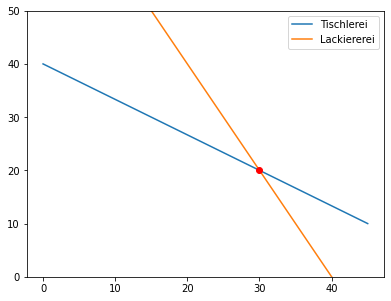

In [ ]:
import numpy as np
from scipy import optimize
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize
import matplotlib.pyplot as plt
e = optimize.linprog([-30, -40], A_ub=[[2, 3], [4, 2]], b_ub=[120, 160])
x = np.linspace(0, 45, 100)
plt.plot(x, (120 - 2 * x) / 3, label='Tischlerei')
plt.plot(x, (160 - 4 * x) / 2, label='Lackiererei')
plt.plot(e.x[0], e.x[1], 'ro')
plt.ylim(0, 50)
plt.legend()
plt.show()
```

</details>

#### Aufgabe 4.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from scipy import optimize

e = optimize.linprog([-1, -1], A_ub=[[1, 1]], b_ub=[10], bounds=[(0, 4), (0, 4)])
print(round(-e.fun, 4))
print(e.x.round(4))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
8.0
[4. 4.]
```

Gesucht ist das größte `x + y` mit `x + y ≤ 10`, aber beide Variablen sind höchstens 4. Die Bedingung `x + y ≤ 10` spielt deshalb keine Rolle:
Das Beste ist `x = y = 4` mit `x + y = 8.0`. Ausgabe: `8.0` und `[4. 4.]`.

</details>

## 5. Abstände und nächste Nachbarn

#### `spatial.distance`

Das Modul `scipy.spatial` (*räumlich*) rechnet mit Punktmengen. In `spatial.distance` stehen verschiedene **Abstandsmaße**:

- `distance.euclidean(p, q)`: der gewöhnliche (euklidische) Abstand, Luftlinie nach Pythagoras
- `distance.cityblock(p, q)`: der **Manhattan-Abstand** `|x₁ - x₂| + |y₁ - y₂|`, wie in einer Stadt mit rechtwinkligen Straßen
- `distance.cdist(A, B)`: eine **Abstandsmatrix**. Zeile `i`, Spalte `j` enthält den Abstand von Punkt `A[i]` zu `B[j]`.
  Mit `metric='cityblock'` wird der Manhattan-Abstand verwendet.

Die Punkte stehen in 2D-Arrays: eine Zeile pro Punkt.

In [ ]:
import numpy as np
from scipy.spatial import distance

print(distance.euclidean([0, 0], [3, 4]), distance.cityblock([0, 0], [3, 4]))
punkte = np.array([[0, 0], [3, 4], [6, 0]])
print(distance.cdist(punkte, punkte).round(2))
print(distance.cdist(punkte, punkte, metric='cityblock'))

#### Nächste Nachbarn: `spatial.KDTree`

Bei sehr vielen Punkten wäre es zu langsam, für jede Frage alle Abstände zu berechnen. Ein `KDTree` ordnet die Punkte so, dass man schnell suchen kann:

- `baum = spatial.KDTree(punkte)` baut den Suchbaum.
- `abstand, index = baum.query(p)` findet den **nächsten** Punkt zu `p` (seinen Index in `punkte` und den Abstand).
  Mit `k=3` erhält man die drei nächsten als Arrays.
- `baum.query_ball_point(p, r)` gibt eine Liste der Indizes aller Punkte im Abstand höchstens `r` zurück.

In [ ]:
import numpy as np
from scipy import spatial

haltestellen = np.array([[1, 1], [4, 2], [2, 5], [6, 6]])
baum = spatial.KDTree(haltestellen)
abstand, index = baum.query([3, 3])
print(index, round(abstand, 4))
abstaende, indizes = baum.query([3, 3], k=2)
print(indizes, abstaende.round(4))
print(baum.query_ball_point([3, 3], 2.5))

#### Aufgabe 5.1

Gib die Abstandsmatrix der fünf Orte aus (Luftlinie, zwei Nachkommastellen).

**Erwartete Ausgabe:**
```
[[ 0.    5.    7.07  9.43 10.3 ]
 [ 5.    0.    5.    4.47  6.08]
 [ 7.07  5.    0.    7.28  4.47]
 [ 9.43  4.47  7.28  0.    5.  ]
 [10.3   6.08  4.47  5.    0.  ]]
```

In [ ]:
import numpy as np
from scipy import spatial

orte = np.array([[0, 0], [4, 3], [1, 7], [8, 5], [5, 9]])   # in km
namen = ['A', 'B', 'C', 'D', 'E']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import spatial

orte = np.array([[0, 0], [4, 3], [1, 7], [8, 5], [5, 9]])   # in km
namen = ['A', 'B', 'C', 'D', 'E']
print(spatial.distance.cdist(orte, orte).round(2))
```

</details>

#### Aufgabe 5.2

Welche beiden Orte liegen am weitesten auseinander? Gib ihre Namen und den Abstand (zwei Nachkommastellen) aus.
Benutze `argmax()` und `np.unravel_index(i, matrix.shape)`, das aus dem Index im flachen Array Zeile und Spalte macht.

**Erwartete Ausgabe:**
```
A E 10.3
```

In [ ]:
import numpy as np
from scipy import spatial

orte = np.array([[0, 0], [4, 3], [1, 7], [8, 5], [5, 9]])   # in km
namen = ['A', 'B', 'C', 'D', 'E']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import spatial

orte = np.array([[0, 0], [4, 3], [1, 7], [8, 5], [5, 9]])   # in km
namen = ['A', 'B', 'C', 'D', 'E']
d = spatial.distance.cdist(orte, orte)
i, j = np.unravel_index(d.argmax(), d.shape)
print(namen[i], namen[j], round(d[i, j], 2))
```

</details>

#### Aufgabe 5.3

Ein Lager soll an einem der fünf Orte gebaut werden, sodass die **Summe** der Abstände zu allen Orten am kleinsten ist. Gib für jeden Ort die Summe
(zwei Nachkommastellen) und dann den besten Ort aus.

**Erwartete Ausgabe:**
```
A 31.8
B 20.55
C 23.82
D 26.19
E 25.85
B
```

In [ ]:
import numpy as np
from scipy import spatial

orte = np.array([[0, 0], [4, 3], [1, 7], [8, 5], [5, 9]])   # in km
namen = ['A', 'B', 'C', 'D', 'E']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import spatial

orte = np.array([[0, 0], [4, 3], [1, 7], [8, 5], [5, 9]])   # in km
namen = ['A', 'B', 'C', 'D', 'E']
summen = spatial.distance.cdist(orte, orte).sum(axis=1)
for name, s in zip(namen, summen):
    print(name, round(s, 2))
print(namen[summen.argmin()])
```

</details>

#### Aufgabe 5.4

In Manhattan fährt ein Taxi nur waagerecht und senkrecht. Gib die Abstandsmatrix der fünf Orte mit dem Manhattan-Abstand aus und das Paar von Orten,
bei dem der Unterschied zwischen Manhattan-Abstand und Luftlinie am größten ist (Namen und Unterschied, zwei Nachkommastellen).

**Erwartete Ausgabe:**
```
[[ 0.  7.  8. 13. 14.]
 [ 7.  0.  7.  6.  7.]
 [ 8.  7.  0.  9.  6.]
 [13.  6.  9.  0.  7.]
 [14.  7.  6.  7.  0.]]
A E 3.7
```

In [ ]:
import numpy as np
from scipy import spatial

orte = np.array([[0, 0], [4, 3], [1, 7], [8, 5], [5, 9]])   # in km
namen = ['A', 'B', 'C', 'D', 'E']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import spatial

orte = np.array([[0, 0], [4, 3], [1, 7], [8, 5], [5, 9]])   # in km
namen = ['A', 'B', 'C', 'D', 'E']
m = spatial.distance.cdist(orte, orte, metric='cityblock')
print(m)
u = m - spatial.distance.cdist(orte, orte)
i, j = np.unravel_index(u.argmax(), u.shape)
print(namen[i], namen[j], round(u[i, j], 2))
```

</details>

#### Aufgabe 5.5

Für jeden Ort ist der **nächste andere** Ort gesucht. Frage dafür mit `k=2` die zwei nächsten Punkte ab (der nächste ist der Ort selbst mit Abstand 0)
und gib für jeden Ort den Namen des Nachbarn und den Abstand (zwei Nachkommastellen) aus.

**Erwartete Ausgabe:**
```
A B 5.0
B D 4.47
C E 4.47
D B 4.47
E C 4.47
```

In [ ]:
import numpy as np
from scipy import spatial

orte = np.array([[0, 0], [4, 3], [1, 7], [8, 5], [5, 9]])   # in km
namen = ['A', 'B', 'C', 'D', 'E']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import spatial

orte = np.array([[0, 0], [4, 3], [1, 7], [8, 5], [5, 9]])   # in km
namen = ['A', 'B', 'C', 'D', 'E']
baum = spatial.KDTree(orte)
for i in range(len(orte)):
    abstaende, indizes = baum.query(orte[i], k=2)
    print(namen[i], namen[indizes[1]], round(abstaende[1], 2))
```

</details>

#### Aufgabe 5.6

In einem Park stehen Notrufsäulen. Gib für jeden Wanderer die Nummer (Index) der nächsten Säule und den Abstand in m aus (eine Nachkommastelle).

**Erwartete Ausgabe:**
```
1 180.3
4 158.1
2 156.2
3 100.5
```

In [ ]:
import numpy as np
from scipy import spatial

saeulen = np.array([[120, 80], [450, 300], [200, 520], [700, 150], [650, 600]])
wanderer = np.array([[300, 200], [600, 450], [100, 400], [690, 50]])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import spatial

saeulen = np.array([[120, 80], [450, 300], [200, 520], [700, 150], [650, 600]])
wanderer = np.array([[300, 200], [600, 450], [100, 400], [690, 50]])
baum = spatial.KDTree(saeulen)
for w in wanderer:
    abstand, index = baum.query(w)
    print(index, round(abstand, 1))
```

</details>

#### Aufgabe 5.7

Erzeuge mit `rng = np.random.default_rng(12)` 500 zufällige Punkte im Quadrat von 0 bis 100 (`rng.uniform(0, 100, size=(500, 2))`). Wie viele davon liegen
höchstens 10 vom Mittelpunkt (50 | 50) entfernt? Zähle mit `query_ball_point()` und vergleiche mit dem erwarteten Wert `500 · π · 10² / 100²` (zwei Nachkommastellen).

**Erwartete Ausgabe:**
```
14
15.71
```

In [ ]:
import numpy as np
from scipy import spatial
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import spatial
rng = np.random.default_rng(12)
punkte = rng.uniform(0, 100, size=(500, 2))
baum = spatial.KDTree(punkte)
print(len(baum.query_ball_point([50, 50], 10)))
print(round(500 * np.pi * 10 ** 2 / 100 ** 2, 2))
```

</details>

#### Aufgabe 5.8

Zeichne die Notrufsäulen als rote Quadrate (`'rs'`) und die Wanderer als blaue Punkte. Verbinde jeden Wanderer mit einer grauen Linie mit seiner nächsten Säule.
Sorge mit `plt.axis('equal')` für gleiche Einheiten auf beiden Achsen.

**Erwartete Ausgabe:**

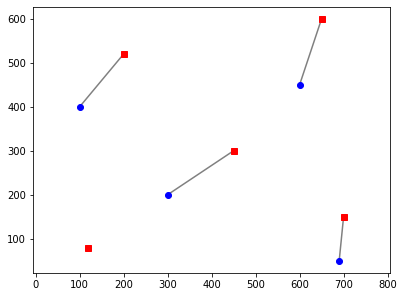

In [ ]:
import numpy as np
from scipy import spatial
import matplotlib.pyplot as plt

saeulen = np.array([[120, 80], [450, 300], [200, 520], [700, 150], [650, 600]])
wanderer = np.array([[300, 200], [600, 450], [100, 400], [690, 50]])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import spatial
import matplotlib.pyplot as plt

saeulen = np.array([[120, 80], [450, 300], [200, 520], [700, 150], [650, 600]])
wanderer = np.array([[300, 200], [600, 450], [100, 400], [690, 50]])
baum = spatial.KDTree(saeulen)
for w in wanderer:
    abstand, index = baum.query(w)
    s = saeulen[index]
    plt.plot([w[0], s[0]], [w[1], s[1]], color='gray')
plt.plot(saeulen[:, 0], saeulen[:, 1], 'rs')
plt.plot(wanderer[:, 0], wanderer[:, 1], 'bo')
plt.axis('equal')
plt.show()
```

</details>

#### Aufgabe 5.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np
from scipy import spatial

punkte = np.array([[0, 0], [10, 0], [0, 10]])
baum = spatial.KDTree(punkte)
abstand, index = baum.query([1, 8])
print(index, round(abstand, 4))
print(spatial.distance.cityblock([0, 0], [-2, 5]))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
2 2.2361
7
```

- Der Punkt (1 | 8) liegt am nächsten an (0 | 10), das ist Index `2`. Der Abstand ist `√(1² + 2²) = √5 ≈ 2.2361`.
- Der Manhattan-Abstand ist `|0 - (-2)| + |0 - 5| = 2 + 5 = 7`.

</details>

## 6. Konstanten und Einheiten

#### `scipy.constants`

Das Modul `scipy.constants` enthält Naturkonstanten und Umrechnungsfaktoren in **SI-Einheiten** (Meter, Kilogramm, Sekunde, ...):

| Name | Bedeutung |
|---|---|
| `constants.g` | Fallbeschleunigung 9.80665 m/s² (Normwert) |
| `constants.c` | Lichtgeschwindigkeit in m/s |
| `constants.G` | Gravitationskonstante |
| `constants.h` | Plancksches Wirkungsquantum |
| `constants.minute`, `constants.hour`, `constants.day`, `constants.year` | Zeitspannen in Sekunden |
| `constants.kilo`, `constants.mega`, `constants.milli`, ... | Vorsilben als Faktor (1000, 10⁶, 0.001) |
| `constants.kmh`, `constants.mile`, `constants.inch` | 1 km/h in m/s, 1 Meile und 1 Zoll in Meter |

`constants.convert_temperature(wert, 'Celsius', 'Kelvin')` rechnet Temperaturen um (auch `'Fahrenheit'`).

In [ ]:
from scipy import constants

print(constants.g, constants.c)
print(constants.hour, constants.day)
print(round(constants.mile, 3), constants.inch)
print(round(100 * constants.kmh, 4))
print(constants.convert_temperature(100, 'Celsius', 'Fahrenheit'))
print(constants.convert_temperature(0, 'Celsius', 'Kelvin'))

#### Aufgabe 6.1

Wie lange braucht das Licht von der Sonne zur Erde (150 Millionen km)? Gib die Zeit in Sekunden und in Minuten aus (zwei Nachkommastellen) und benutze
`constants.c`, `constants.kilo`, `constants.mega` und `constants.minute`.

**Erwartete Ausgabe:**
```
500.35
8.34
```

In [ ]:
from scipy import constants
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import constants
strecke = 150 * constants.mega * constants.kilo
zeit = strecke / constants.c
print(round(zeit, 2))
print(round(zeit / constants.minute, 2))
```

</details>

#### Aufgabe 6.2

Ein Lichtjahr ist die Strecke, die das Licht in einem Jahr zurücklegt. Gib sie in km aus (`:.4e`). Der nächste Stern ist 4.24 Lichtjahre entfernt.
Wie viele Jahre bräuchte eine Raumsonde mit 60 000 km/h (eine Nachkommastelle)?

**Erwartete Ausgabe:**
```
9.4543e+12
76267.2
```

In [ ]:
from scipy import constants
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import constants
lichtjahr = constants.c * constants.year
print(f'{lichtjahr / constants.kilo:.4e}')
geschwindigkeit = 60000 * constants.kmh
print(round(4.24 * lichtjahr / geschwindigkeit / constants.year, 1))
```

</details>

#### Aufgabe 6.3

Rechne die Temperaturen -40, 0, 37 und 100 °C in Fahrenheit und Kelvin um (zwei Nachkommastellen). `convert_temperature()` nimmt auch ein Array.

**Erwartete Ausgabe:**
```
[-40.   32.   98.6 212. ]
[233.15 273.15 310.15 373.15]
```

In [ ]:
import numpy as np
from scipy import constants
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import constants
celsius = np.array([-40, 0, 37, 100])
print(constants.convert_temperature(celsius, 'Celsius', 'Fahrenheit').round(2))
print(constants.convert_temperature(celsius, 'Celsius', 'Kelvin').round(2))
```

</details>

#### Aufgabe 6.4

Ein Stein fällt ohne Luftwiderstand von einem 80 m hohen Turm. Berechne mit `constants.g` die Fallzeit `√(2h / g)` (zwei Nachkommastellen) und die
Aufprallgeschwindigkeit `g · t` in m/s und in km/h (eine Nachkommastelle).

**Erwartete Ausgabe:**
```
4.04
39.6 142.6
```

In [ ]:
import numpy as np
from scipy import constants
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import constants
zeit = np.sqrt(2 * 80 / constants.g)
v = constants.g * zeit
print(round(zeit, 2))
print(round(v, 1), round(v / constants.kmh, 1))
```

</details>

#### Aufgabe 6.5

Ein Fernseher hat eine Bildschirmdiagonale von 55 Zoll im Format 16 : 9. Gib die Diagonale, die Breite und die Höhe in cm aus (eine Nachkommastelle).
Die Breite ist `d · 16 / √(16² + 9²)`.

**Erwartete Ausgabe:**
```
139.7
121.8 68.5
```

In [ ]:
import numpy as np
from scipy import constants
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import constants
d = 55 * constants.inch * 100
print(round(d, 1))
print(round(d * 16 / np.sqrt(16 ** 2 + 9 ** 2), 1), round(d * 9 / np.sqrt(16 ** 2 + 9 ** 2), 1))
```

</details>

#### Aufgabe 6.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from scipy import constants

print(constants.kilo * constants.milli)
print(constants.hour / constants.minute)
print(constants.convert_temperature(273.15, 'Kelvin', 'Celsius'))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
1.0
60.0
0.0
```

- `kilo` ist 1000, `milli` ist 0.001, das Produkt `1.0`.
- Eine Stunde hat 3600 Sekunden, eine Minute 60, also `60.0`.
- 273.15 K sind genau 0 °C: `0.0`.

</details>

## 7. Gemischte Übungen

#### Aufgabe 7.1

**Wurf mit Luftwiderstand:** Ein Ball wird unter 45° mit 20 m/s geworfen. Für die Größen `[x, y, vx, vy]` gilt `x' = vx`, `y' = vy`,
`vx' = -0.02 · v · vx`, `vy' = -9.81 - 0.02 · v · vy` mit `v = √(vx² + vy²)`. Bestimme mit `dense_output=True` und `brentq()` (Höhe 0 zwischen 1 und 5),
wann und wie weit vom Abwurf der Ball landet (zwei Nachkommastellen, `rtol=1e-8, atol=1e-8`). Ohne Luftwiderstand wären es `20² / 9.81` Meter.

**Erwartete Ausgabe:**
```
2.52 25.83
40.77
```

In [ ]:
import numpy as np
from scipy import integrate, optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate, optimize


def wurf(t, z):
    x, y, vx, vy = z
    v = np.sqrt(vx ** 2 + vy ** 2)
    return [vx, vy, -0.02 * v * vx, -9.81 - 0.02 * v * vy]


v0 = 20 / np.sqrt(2)
loesung = integrate.solve_ivp(wurf, (0, 5), [0, 0, v0, v0], dense_output=True, rtol=1e-8, atol=1e-8)


def hoehe(t):
    return loesung.sol(t)[1]


landung = optimize.brentq(hoehe, 1, 5)
print(round(landung, 2), round(loesung.sol(landung)[0], 2))
print(round(20 ** 2 / 9.81, 2))
```

</details>

#### Aufgabe 7.2

Zeichne die Flugbahn des Balls aus der vorigen Aufgabe (`y` über `x`, 200 Punkte von 0 bis zur Landezeit) und zum Vergleich die Bahn ohne Luftwiderstand
(`vx' = 0`, `vy' = -9.81`, gestrichelt). Zeige nur Höhen ab 0 (`plt.ylim(bottom=0)`) und benutze `plt.axis('equal')` nicht.

**Erwartete Ausgabe:**

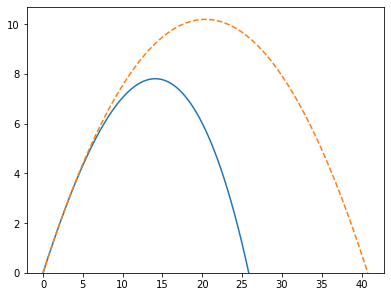

In [ ]:
import numpy as np
from scipy import integrate, optimize
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate, optimize
import matplotlib.pyplot as plt


def wurf(t, z, k):
    x, y, vx, vy = z
    v = np.sqrt(vx ** 2 + vy ** 2)
    return [vx, vy, -k * v * vx, -9.81 - k * v * vy]


v0 = 20 / np.sqrt(2)
for k, stil in [(0.02, '-'), (0, '--')]:
    loesung = integrate.solve_ivp(wurf, (0, 5), [0, 0, v0, v0], args=(k,), dense_output=True, rtol=1e-8, atol=1e-8)

    def hoehe(t):
        return loesung.sol(t)[1]

    landung = optimize.brentq(hoehe, 1, 5)
    werte = loesung.sol(np.linspace(0, landung, 200))
    plt.plot(werte[0], werte[1], stil)
plt.ylim(bottom=0)
plt.show()
```

</details>

#### Aufgabe 7.3

Ein Paketdienst hat drei Depots und sechs Kunden. Ordne jeden Kunden dem nächsten Depot zu (`KDTree`) und gib für jedes Depot die Indizes seiner Kunden
und die Summe der Abstände (eine Nachkommastelle) aus.

**Erwartete Ausgabe:**
```
0 [0 1] 3.7
1 [2 3] 4.5
2 [4 5] 2.8
```

In [ ]:
import numpy as np
from scipy import spatial

depots = np.array([[2, 2], [8, 3], [5, 8]])
kunden = np.array([[1, 4], [3, 1], [7, 1], [9, 5], [4, 7], [6, 9]])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import spatial

depots = np.array([[2, 2], [8, 3], [5, 8]])
kunden = np.array([[1, 4], [3, 1], [7, 1], [9, 5], [4, 7], [6, 9]])
baum = spatial.KDTree(depots)
abstaende, zuordnung = baum.query(kunden)
for d in range(len(depots)):
    print(d, np.where(zuordnung == d)[0], round(abstaende[zuordnung == d].sum(), 1))
```

</details>

#### Aufgabe 7.4

**Wie lange reicht ein Vorrat?** Ein Wasserspeicher enthält 5000 Liter. Pro Stunde werden `400 + 150 · sin(π t / 12)` Liter entnommen, und es fließen
konstant 300 Liter zu. Bestimme mit `solve_ivp()`, `dense_output=True` und `brentq()` (zwischen 1 und 100), wann der Speicher leer ist (zwei Nachkommastellen).

**Erwartete Ausgabe:**
```
49.54
```

In [ ]:
import numpy as np
from scipy import integrate, optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate, optimize


def rate(t, y):
    return 300 - (400 + 150 * np.sin(np.pi * t / 12))


loesung = integrate.solve_ivp(rate, (0, 100), [5000], dense_output=True, rtol=1e-8, atol=1e-8)


def menge(t):
    return loesung.sol(t)[0]


print(round(optimize.brentq(menge, 1, 100), 2))
```

</details>

#### Aufgabe 7.5

Eine Schule plant ein Sommerfest und verkauft Waffeln (Gewinn 0.80 €) und Crêpes (Gewinn 1.20 €). Teig: 0.1 kg pro Waffel und 0.08 kg pro Crêpe,
40 kg sind da. Zeit: 2 Minuten pro Waffel, 4 Minuten pro Crêpe, 1200 Minuten stehen zur Verfügung. Es sollen mindestens 100 Waffeln sein.
Bestimme die beste Aufteilung (ganzzahlig) und den Gewinn.

**Erwartete Ausgabe:**
```
[266. 167.]
413.2
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize
e = optimize.linprog([-0.8, -1.2], A_ub=[[0.1, 0.08], [2, 4]], b_ub=[40, 1200], bounds=[(100, None), (0, None)], integrality=[1, 1])
print(e.x)
print(round(-e.fun, 2))
```

</details>

#### Aufgabe 7.6

Denk dir selbst ein Modell mit einer Änderungsrate aus (z. B. das Abkühlen deines Tees, das Füllen einer Badewanne mit offenem Abfluss, die Ausbreitung
eines Gerüchts) und berechne und zeichne den Verlauf mit `solve_ivp()`.

In [ ]:
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt


def geruecht(t, y, k, n):
    return k * y * (n - y) / n


loesung = integrate.solve_ivp(geruecht, (0, 14), [2], t_eval=np.linspace(0, 14, 200), args=(0.9, 1200), rtol=1e-8, atol=1e-8)
plt.plot(loesung.t, loesung.y[0])
plt.xlabel('Tage')
plt.ylabel('Personen, die es wissen')
plt.show()
```

</details>